In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

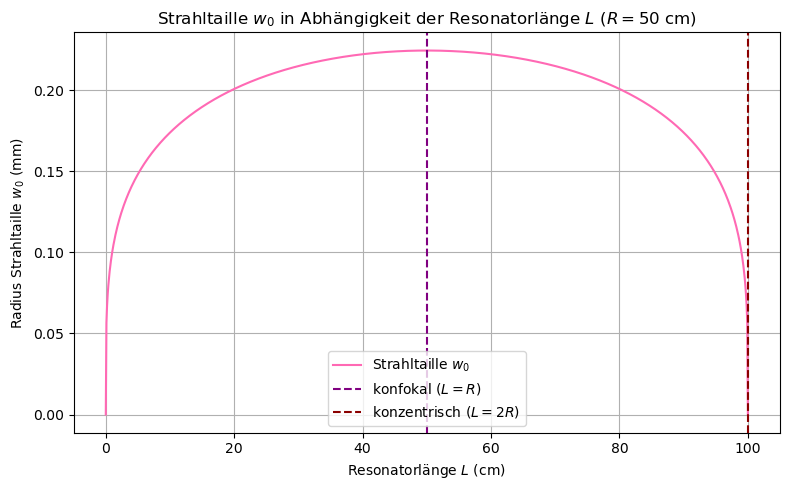

In [ ]:

R = 0.50 #  m
lambda_ = 632.8e-9 # Wellenlänge HeNe-Laser 

L = np.linspace(0, 2*R, 1000)

# Berechnung der Strahltaille w0
# Formel: w0 = sqrt( (lambda / 2*pi) * sqrt(L * (2R - L)) )
w_0_sq = (lambda_ / (2 * np.pi)) * np.sqrt(L * (2 * R - L))
w_0 = np.sqrt(w_0_sq)

# Einheiten anpassen für den Plot
L_cm = L * 100 # L von m in cm
w_0_mm = w_0 * 1000 # w0 von m in mm

# Plot 
plt.figure(figsize=(8, 5))
plt.plot(L_cm, w_0_mm, label='Strahltaille $w_0$', color='hotpink')

# Markierungen für konfokal und konzentrisch
plt.axvline(x=50, color='purple', linestyle='--', label='konfokal ($L=R$)')
plt.axvline(x=100, color='darkred', linestyle='--', label='konzentrisch ($L=2R$)')

plt.title('Strahltaille $w_0$ in Abhängigkeit der Resonatorlänge $L$ ($R=50$ cm)')
plt.xlabel('Resonatorlänge $L$ (cm)')
plt.ylabel('Radius Strahltaille $w_0$ (mm)')
plt.grid(True)
plt.legend()
plt.tight_layout()
#plt.savefig('strahltaille_r=50cm.png')

In [9]:
# 3. TABELLE ALS PANDAS DATAFRAME
# ---------------------------------------------------------
# Ausgewählte Punkte für die Tabelle (in cm)
L_table_cm = np.array([0, 10, 25, 50, 75, 90, 95, 99, 100])
L_table_m = L_table_cm / 100 # Umrechnung für die Formel

# Berechnung für die Tabellenwerte
w_0_table = np.sqrt((lambda_ / (2 * np.pi)) * np.sqrt(L_table_m * (2 * R - L_table_m)))

# DataFrame erstellen
df = pd.DataFrame({
    'Resonatorlänge L (cm)': L_table_cm,
    'Strahltaille w_0 (mm)': np.round(w_0_table * 1000, 3)
})

# Zusätzliche Info-Spalte
bedingungen = {0: "Theoretischer Grenzfall", 50: "Konfokal (Maximum)", 100: "Konzentrisch (Stabilitätsgrenze)"}
df['Anmerkung'] = df['Resonatorlänge L (cm)'].map(bedingungen).fillna("")

# Ausgabe der Tabelle (In Jupyter wird die letzte Variable automatisch schön formatiert gerendert)
display(df)

,Resonatorlänge L (cm),Strahltaille w_0 (mm),Anmerkung
0,0,0.000,Theoretischer Grenzfall
1,10,0.174,
2,25,0.209,
3,50,0.224,Konfokal (Maximum)
4,75,0.209,
5,90,0.174,
6,95,0.148,
7,99,0.100,
8,100,0.000,Konzentrisch (Stabilitätsgrenze)


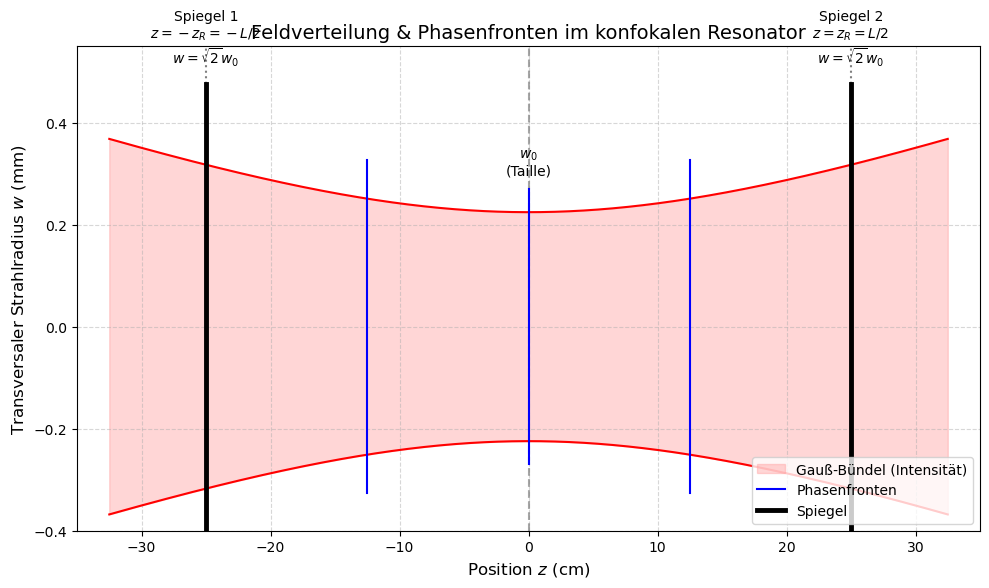

In [10]:
# Parameter
L = 0.50  # Resonatorlänge in m (50 cm)
R_mirror = L  # Konfokale Bedingung R = L
z_R = L / 2  # Rayleigh-Länge (beim konfokalen Resonator exakt L/2)
lambda_ = 632.8e-9  # Wellenlänge HeNe-Laser
w_0 = np.sqrt(lambda_ * z_R / np.pi)  # Strahltaille

# z-Achse für den Plot (etwas über die Spiegel hinaus)
z = np.linspace(-L/2 * 1.3, L/2 * 1.3, 1000)

# Ausbreitung des Strahlradius w(z)
w = w_0 * np.sqrt(1 + (z / z_R)**2)

plt.figure(figsize=(10, 6))

# Gaußstrahl-Profil füllen und Ränder zeichnen
plt.fill_between(z * 100, w * 1000, -w * 1000, color='#ff9999', alpha=0.4, label='Gauß-Bündel (Intensität)')
plt.plot(z * 100, w * 1000, color='red', linewidth=1.5)
plt.plot(z * 100, -w * 1000, color='red', linewidth=1.5)

# Strahltaille w_0 markieren
plt.axvline(0, color='gray', linestyle='--', alpha=0.7)
plt.text(0, w_0 * 1000 * 1.3, '$w_0$\n(Taille)', ha='center', va='bottom', color='black')

# Rayleigh-Länge z_R = L/2 markieren (Spiegelpositionen)
plt.axvline(z_R * 100, color='black', linestyle=':', alpha=0.5)
plt.axvline(-z_R * 100, color='black', linestyle=':', alpha=0.5)

# Funktion zum Zeichnen von Phasenfronten/Spiegeln (paraxiale Näherung)
def draw_phase_front(z_center, R_curvature, extent_y, is_mirror=False):
    # y-Werte transversal
    y = np.linspace(-extent_y, extent_y, 100)
    # Wölbung dz = y^2 / (2R)
    dz = y**2 / (2 * R_curvature)
    
    color = 'blue' if not is_mirror else 'black'
    linewidth = 1.5 if not is_mirror else 3.5
    label = 'Spiegel' if is_mirror and z_center > 0 else None
    label_pf = 'Phasenfronten' if not is_mirror and z_center == 0 else None
    
    plt.plot((z_center - dz) * 100, y * 1000, color=color, linewidth=linewidth, label=label or label_pf)

# 1. Plane Phasenfront in der Mitte (z=0 -> R=unendlich, dz=0)
plt.plot([0, 0], [-w_0*1000*1.2, w_0*1000*1.2], color='blue', linewidth=1.5, label='Phasenfronten')

# 2. Spiegel an den Positionen z = +- L/2 mit Krümmung R = +- L
w_mirror = w_0 * np.sqrt(2)
draw_phase_front(L/2, L, w_mirror * 1.5, is_mirror=True)
draw_phase_front(-L/2, -L, w_mirror * 1.5, is_mirror=True)

# Beschriftung der Spiegel
plt.text(L/2 * 100, w_mirror * 1000 * 1.6, 'Spiegel 2\n$z = z_R = L/2$\n$w = \sqrt{2} w_0$', ha='center', va='bottom')
plt.text(-L/2 * 100, w_mirror * 1000 * 1.6, 'Spiegel 1\n$z = -z_R = -L/2$\n$w = \sqrt{2} w_0$', ha='center', va='bottom')

# 3. Allgemeine Positionen z1, z2 (als blaue Phasenfronten auf halber Strecke)
z_f = L/4
R_f = z_f + z_R**2 / z_f
w_f = w_0 * np.sqrt(1 + (z_f / z_R)**2)
draw_phase_front(z_f, R_f, w_f * 1.3)
draw_phase_front(-z_f, -R_f, w_f * 1.3)

# Plot anpassen
plt.title('Feldverteilung & Phasenfronten im konfokalen Resonator', fontsize=14)
plt.xlabel('Position $z$ (cm)', fontsize=12)
plt.ylabel('Transversaler Strahlradius $w$ (mm)', fontsize=12)
plt.xlim(-35, 35)
plt.ylim(-0.4, 0.55)

# Doppelte Labels in der Legende vermeiden
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc='lower right')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
#plt.savefig('konfokal_feld.png')